Q8: Interacting with Web APIs

Analyzing weather data for London using OpenWeatherMap.

Install requests, pandas, seaborn, matplotlib and folium. Paste your API key in the first code cell before running.

The saved outputs were generated from a live OpenWeatherMap forecast for London.

The map compares mean temperature, mean humidity and total forecast rain for London, Paris and Manchester. Daily aggregation uses UTC dates.

In [1]:
import requests
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import folium

# Enter the API key
API_KEY = "PASTE_YOUR_API_KEY_HERE"
city = "London"
url = "https://api.openweathermap.org/data/2.5/forecast"
params = {"q": city, "appid": API_KEY, "units": "metric"}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()
data = response.json()
print(data)

{'cod': '200', 'message': 0, 'cnt': 40, 'list': [{'dt': 1793091600, 'main': {'temp': 13.57, 'feels_like': 13.38, 'temp_min': 13.57, 'temp_max': 13.57, 'pressure': 1008, 'sea_level': 1008, 'grnd_level': 1005, 'humidity': 92, 'temp_kf': 0, 'dew_point': 12.3}, 'weather': [{'id': 500, 'main': 'Rain', 'description': 'light rain', 'icon': '10d'}], 'clouds': {'all': 100}, 'wind': {'speed': 4.51, 'deg': 235, 'gust': 11.03}, 'visibility': 7093, 'pop': 0.96, 'rain': {'3h': 2}, 'sys': {'pod': 'd'}, 'dt_txt': '2026-10-27 09:00:00'}, {'dt': 1793102400, 'main': {'temp': 13.84, 'feels_like': 13.5, 'temp_min': 13.84, 'temp_max': 14.39, 'pressure': 1009, 'sea_level': 1009, 'grnd_level': 1008, 'humidity': 85, 'temp_kf': -0.55, 'dew_point': 11.36}, 'weather': [{'id': 500, 'main': 'Rain', 'description': 'light rain', 'icon': '10d'}], 'clouds': {'all': 72}, 'wind': {'speed': 5.31, 'deg': 249, 'gust': 12.46}, 'visibility': 10000, 'pop': 0.36, 'rain': {'3h': 0.28}, 'sys': {'pod': 'd'}, 'dt_txt': '2026-10-27 

In [2]:
# Extract weather data
records = []
for record in data["list"]:
    weather = {
        "Date": record["dt_txt"],
        "Temperature": record["main"]["temp"],
        "Humidity": record["main"]["humidity"],
        "Wind_Speed": record["wind"]["speed"],
        "Rain": record.get("rain", {}).get("3h", 0)
    }
    records.append(weather)

df = pd.DataFrame(records)
print("Weather Data:")
print(df.head())
print("\nShape:", df.shape)

Weather Data:
                  Date  Temperature  Humidity  Wind_Speed  Rain
0  2026-10-27 09:00:00        13.57        92        4.51  2.00
1  2026-10-27 12:00:00        13.84        85        5.31  0.28
2  2026-10-27 15:00:00        13.82        70        4.57  0.18
3  2026-10-27 18:00:00        10.96        73        3.35  0.00
4  2026-10-27 21:00:00        10.12        78        3.28  0.00

Shape: (40, 5)


In [3]:
# Clean the data
df["Date"] = pd.to_datetime(df["Date"], errors="coerce", utc=True)
df = df.dropna().drop_duplicates()
df = df.sort_values("Date").reset_index(drop=True)
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Date           0
Temperature    0
Humidity       0
Wind_Speed     0
Rain           0
dtype: int64


In [4]:
# Calculate weather statistics
print("Average Temperature:", df["Temperature"].mean())
print("Maximum Temperature:", df["Temperature"].max())
print("Minimum Temperature:", df["Temperature"].min())
print("Average Humidity:", df["Humidity"].mean())
print("Total Rain:", df["Rain"].sum())

# Daily aggregation
daily = df.groupby(df["Date"].dt.date).agg({
    "Temperature": "mean",
    "Humidity": "mean",
    "Wind_Speed": "mean",
    "Rain": "sum"
})

print("\nDaily Weather Summary (UTC):")
print(daily)

Average Temperature: 10.177499999999998
Maximum Temperature: 14.77
Minimum Temperature: 6.09
Average Humidity: 89.1
Total Rain: 2.4600000000000004

Daily Weather Summary (UTC):
            Temperature  Humidity  Wind_Speed  Rain
Date                                               
2026-10-27    12.462000    79.600    4.204000  2.46
2026-10-28    10.810000    81.625    2.903750  0.00
2026-10-29    10.291250    94.000    1.218750  0.00
2026-10-30    10.568750    89.500    1.621250  0.00
2026-10-31     8.847500    93.875    1.208750  0.00
2026-11-01     6.883333    98.000    0.633333  0.00


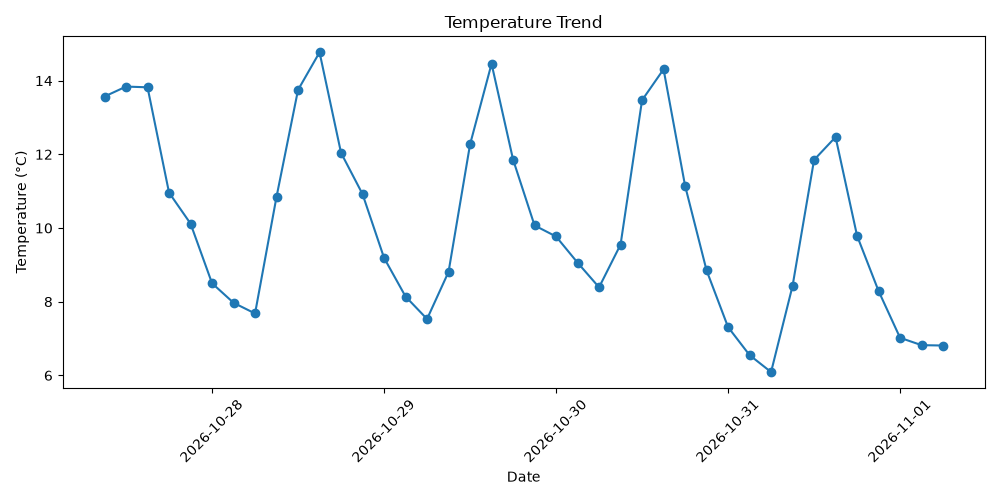

In [5]:
# Temperature trend
plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Temperature"], marker="o")
plt.title("Temperature Trend")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

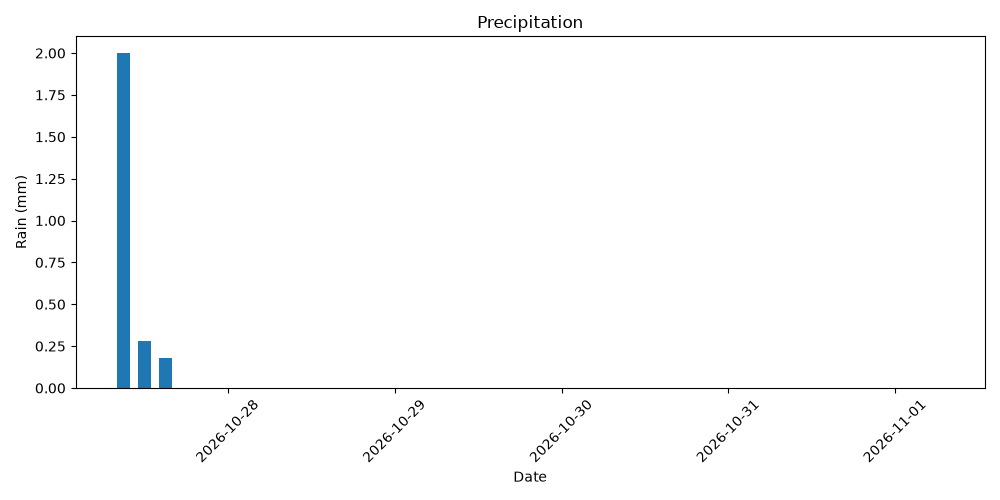

In [6]:
# Rainfall
plt.figure(figsize=(10, 5))
plt.bar(df["Date"], df["Rain"], width=0.08)
plt.title("Precipitation")
plt.xlabel("Date")
plt.ylabel("Rain (mm)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

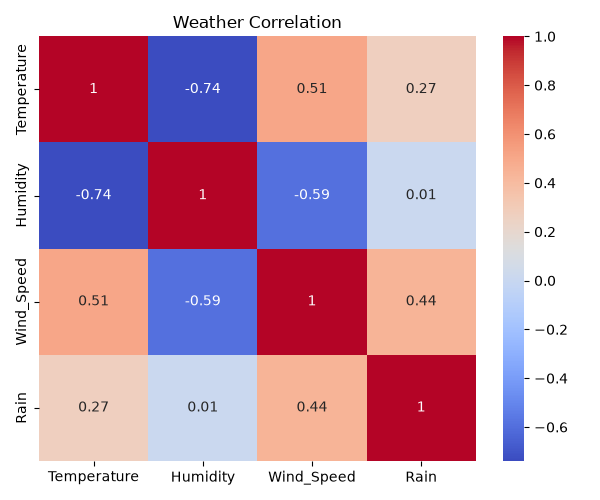

In [7]:
# Correlation heatmap
corr = df[["Temperature", "Humidity", "Wind_Speed", "Rain"]].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Weather Correlation")
plt.tight_layout()
plt.show()

In [8]:
# Compare weather across cities on a map
cities = [city, "Paris", "Manchester"]
m = folium.Map(location=[data["city"]["coord"]["lat"], data["city"]["coord"]["lon"]], zoom_start=5)
city_summaries = []

for place in cities:
    if place == city:
        forecast_data = data
    else:
        response = requests.get(url, params={"q": place, "appid": API_KEY, "units": "metric"}, timeout=30)
        response.raise_for_status()
        forecast_data = response.json()

    items = forecast_data["list"]
    temperature = sum(item["main"]["temp"] for item in items) / len(items)
    humidity = sum(item["main"]["humidity"] for item in items) / len(items)
    rain = sum(item.get("rain", {}).get("3h", 0) for item in items)
    lat = forecast_data["city"]["coord"]["lat"]
    lon = forecast_data["city"]["coord"]["lon"]
    popup = (f"{place}<br>Mean temperature: {temperature:.2f} °C"
             f"<br>Mean humidity: {humidity:.1f}%<br>Total forecast rain: {rain:.2f} mm"
             f"<br>UTC: {items[0]['dt_txt']} to {items[-1]['dt_txt']}")
    folium.CircleMarker(
        location=[lat, lon], radius=8 + rain, color="blue", fill=True,
        popup=folium.Popup(popup, max_width=300), tooltip=place
    ).add_to(m)
    city_summaries.append({"City": place, "Temperature": temperature, "Humidity": humidity, "Rain": rain})

print(pd.DataFrame(city_summaries).round(2))
m.fit_bounds(m.get_bounds())
m.save("weather_map.html")
print("Map saved as weather_map.html")

         City  Temperature  Humidity  Rain
0      London        10.18     89.10  2.46
1       Paris        10.18     83.60  1.35
2  Manchester        10.18     87.18  4.46
Map saved as weather_map.html
